In [1]:
## install squidpy
#!python3 -m pip install squidpy
#!python3 -m pip install igraph ## for leiden
#!python3 -m pip install leidenalg
#!python3 -m pip install harmonypy


from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import squidpy as sq

os.makedirs('filter_data_withImage', exist_ok=True)


/homes/zhanyx3/.local/lib/python3.11/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/homes/zhanyx3/.local/lib/python3.11/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/homes/zhanyx3/.local/lib/python3.11/site-packages/anndata/__init__.py:44: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  return module_get_attr_redirect(attr_name, deprecated_mapping=_DEPRECATED)

In [ ]:
### At terminal , create a formatted rawfile directory for downstream sq analysis
#cd ~/PTPN2_ST/

##unzip tar files
#tar -xvzf filename.tar.gz

# create a directory adjacent to RawData and flatFiles
#mkdir -p sample_dir_formatted && cd $_

## cp all the ST data including decoded files under this new location
#scp -r zhanyx3@mghn1.ncsa.illinois.edu:/projects/abv/GRC/nanostring/GTG-2243-PTPN2 .

# Add flat files
#for file in $(ls ./flatFiles/*/*csv*); do mv $file ./; done

# Add folders
#mv ./DecodedFiles/*/*/CellStatsDir/CellComposite ./
#mv ./DecodedFiles/*/*/CellStatsDir/CellOverlay ./

#mkdir -p CellLabels
#for file in $(ls ./DecodedFiles/*/*/CellStatsDir/FOV*/CellLabels*); do mv $file ./CellLabels/ ; done

  
#mkdir -p CompartmentLabels
#for file in $(ls ./DecodedFiles/*/*/CellStatsDir/FOV*/CompartmentLabels*); do mv $file ./CompartmentLabels/ ; done


In [2]:
sample_dir = '/homes/zhanyx3/PTPN2_ST/sample_dir_formatted/GTG-2243-PTPN2/GTG-2243-PTPN2/2503SCRcRcc/'

meta_file = [item for item in os.listdir(sample_dir) if 'metadata_file' in item][0]
counts_file = [item for item in os.listdir(sample_dir) if 'exprMat_file' in item][0]
fov_file = [item for item in os.listdir(sample_dir) if 'fov_positions_file' in item][0]

In [3]:
fov_df = pd.read_csv(os.path.join(sample_dir, fov_file))
if 'FOV' in fov_df.columns:
  print("Refactoring file to older format.")
  # Rename 'FOV' column to 'fov'
  fov_df.rename(columns={'FOV': 'fov'}, inplace=True)
  # have fov_file reference the new, formatted file and write it
  fov_file = os.path.join(sample_dir,'fov_positions_formatted.csv')
  fov_df.to_csv(fov_file, index=False)

adata2 = sq.read.nanostring(
    path=sample_dir,
    counts_file=counts_file,
    meta_file=meta_file,
    fov_file=fov_file
)
    
# This part of the analyis is similar to above
adata2.var["Negative"] = adata2.var_names.str.startswith("Negative")
adata2.var["SystemControl"] = adata2.var_names.str.startswith("SystemControl")
sc.pp.calculate_qc_metrics(adata2, qc_vars=["Negative", "SystemControl"], inplace=True)
sc.pp.filter_cells(adata2, min_counts=250)
sc.pp.filter_genes(adata2, min_cells=1000)
adata2.layers["counts"] = adata2.X.copy()
sc.pp.normalize_total(adata2, inplace=True, exclude_highly_expressed=True)
sc.pp.log1p(adata2)
sc.pp.pca(adata2, n_comps=50)
sc.pp.neighbors(adata2)
sc.tl.umap(adata2, min_dist=0.2, spread=1)
sc.tl.leiden(adata2)
   

Refactoring file to older format.


2025-09-26 18:03:08.171752: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-09-26 18:03:08.189345: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1758927788.204863  461122 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1758927788.209334  461122 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1758927788.221823  461122 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

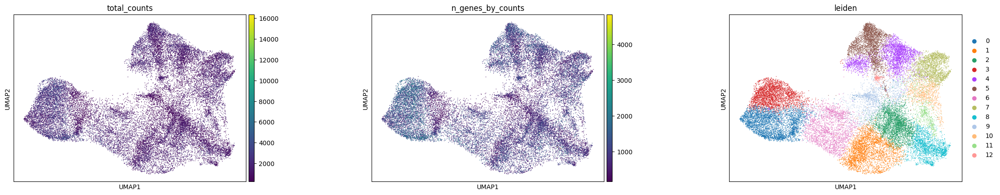

In [4]:
sc.pl.umap(
    adata2,
    color=[
        "total_counts",
        "n_genes_by_counts",
        "leiden",
    ],
    wspace=0.4,
)

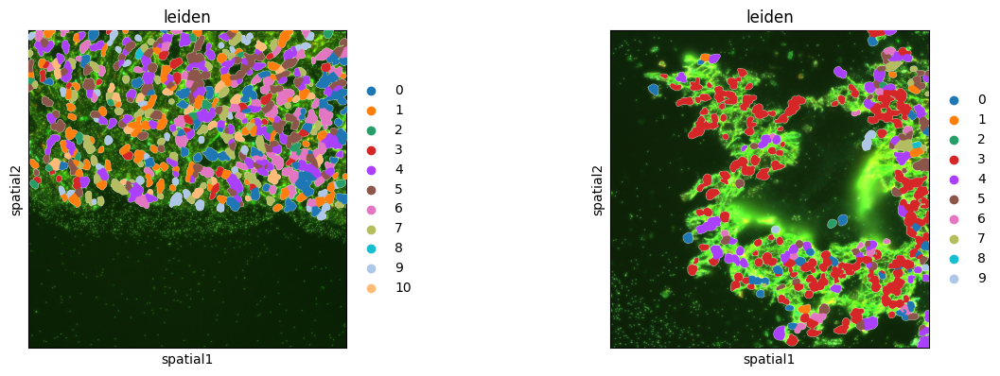

In [5]:
sq.pl.spatial_segment(
    adata2,
    color="leiden",
    library_key="fov",
    library_id=["12", "16"],
    seg_cell_id="cell_ID",
)

/homes/zhanyx3/.local/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:724: FutureWarning: `square` is deprecated since version 0.25 and will be removed in version 0.27. Use `skimage.morphology.footprint_rectangle` instead.
  val_im[val_im == erosion(val_im, square(seg_erosionpx))] = 0


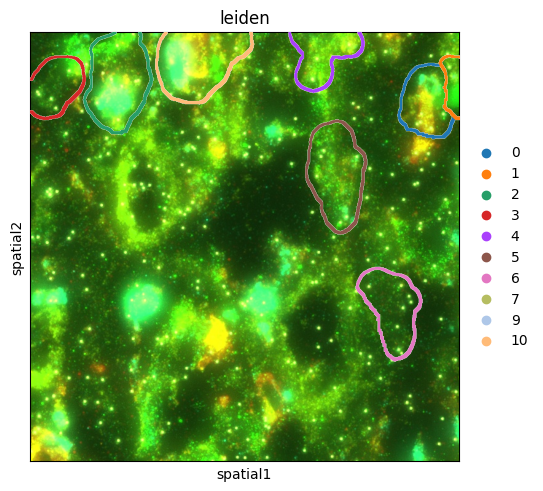

In [6]:
sq.pl.spatial_segment(
    adata2,
    color="leiden",
    library_key="fov",
    library_id="12",
    seg_cell_id="cell_ID",
    seg_contourpx=10,
    crop_coord=[(0, 0, 700, 700)],
)

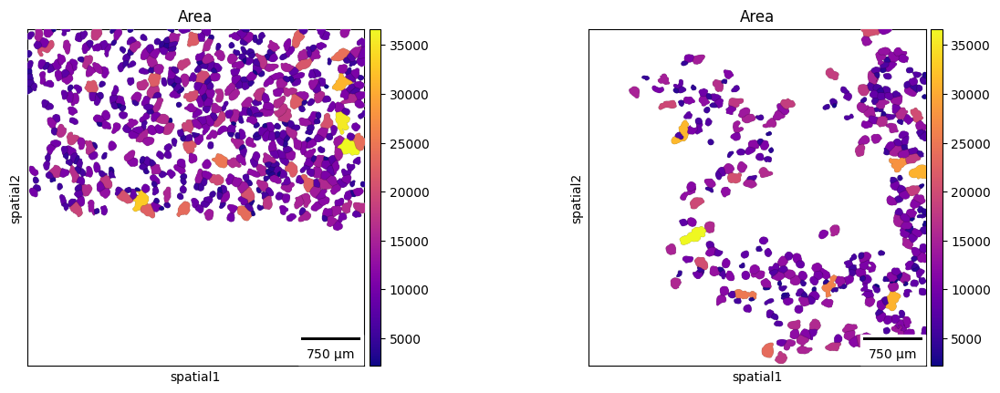

In [7]:
sq.pl.spatial_segment(
    adata2,
    color="Area",
    library_key="fov",
    library_id=["12", "16"],
    seg_cell_id="cell_ID",
    seg_outline=True,
    cmap="plasma",
    img=False,
    scalebar_dx=1.0,
    scalebar_kwargs={"scale_loc": "bottom", "location": "lower right"},
)

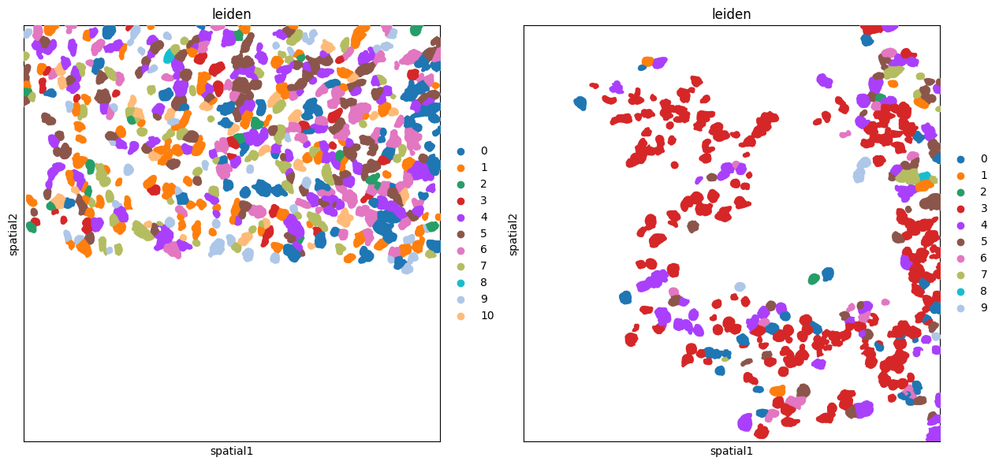

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(15, 7))
sq.pl.spatial_segment(
    adata2,
    shape="hex",
    color="leiden",
    library_key="fov",
    library_id="12",
    seg_cell_id="cell_ID",
    img=False,
    size=60,
    ax=ax[0],
)

sq.pl.spatial_segment(
    adata2,
    color="leiden",
    seg_cell_id="cell_ID",
    library_key="fov",
    library_id="16",
    img=False,
    size=60,
    ax=ax[1],
)

/homes/zhanyx3/.local/lib/python3.11/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/homes/zhanyx3/.local/lib/python3.11/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


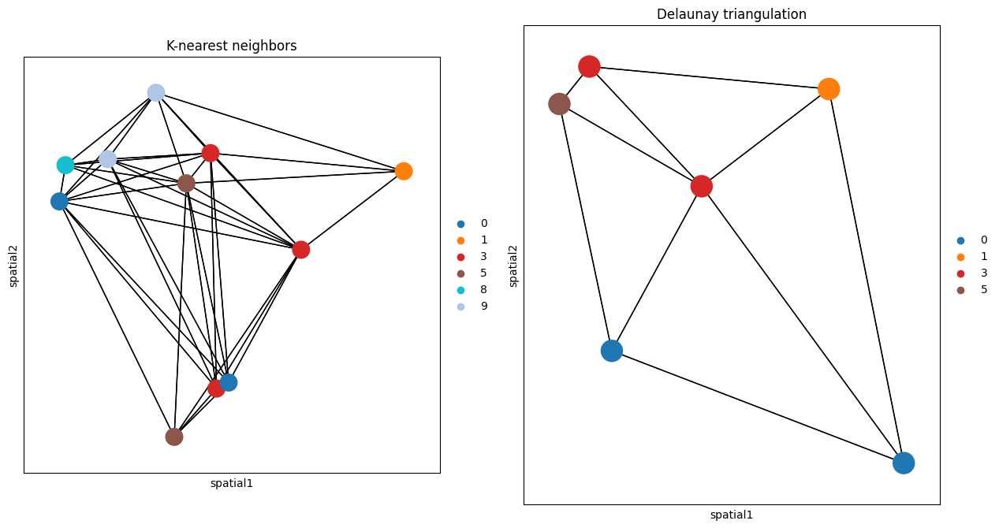

In [9]:
#Computation of spatial statistics
#Building the spatial neighbors graphs

fig, ax = plt.subplots(1, 2, figsize=(15, 15))
sq.gr.spatial_neighbors(
    adata2,
    n_neighs=10,
    coord_type="generic",
)
_, idx = adata2.obsp["spatial_connectivities"][420, :].nonzero()
idx = np.append(idx, 420)
sq.pl.spatial_scatter(
    adata2[idx, :],
    library_id="16",
    color="leiden",
    connectivity_key="spatial_connectivities",
    size=3,
    edges_width=1,
    edges_color="black",
    img=False,
    title="K-nearest neighbors",
    ax=ax[0],
)

sq.gr.spatial_neighbors(
    adata2,
    n_neighs=10,
    coord_type="generic",
    delaunay=True,
)
_, idx = adata2.obsp["spatial_connectivities"][420, :].nonzero()
idx = np.append(idx, 420)
sq.pl.spatial_scatter(
    adata2[idx, :],
    library_id="16",
    color="leiden",
    connectivity_key="spatial_connectivities",
    size=3,
    edges_width=1,
    edges_color="black",
    img=False,
    title="Delaunay triangulation",
    ax=ax[1],
)


In [10]:
#Moran’s I is a useful spatial statistic for measuring the extent that a gene’s expression is clustered in spac

sq.gr.spatial_neighbors(adata2, coord_type="generic", delaunay=True)

sq.gr.spatial_autocorr(
    adata2,
    mode="moran",
    n_perms=100,
    n_jobs=1,
)

adata2.uns["moranI"].head(10)


  0%|          | 0/100 [00:00<?, ?/s]

,I,pval_norm,var_norm,pval_z_sim,pval_sim,var_sim,pval_norm_fdr_bh,pval_z_sim_fdr_bh,pval_sim_fdr_bh
RUNX2,0.014015,0.000022,0.000012,7.800864e-10,0.009901,0.000005,0.034327,8.054392e-07,0.107608
MOV10L1,0.012136,0.000202,0.000012,3.191311e-06,0.009901,0.000007,0.113688,8.237572e-04,0.107608
LAG3,0.011882,0.000266,0.000012,2.234411e-07,0.009901,0.000006,0.117871,1.354709e-04,0.107608
RTN4R,0.011400,0.000444,0.000012,3.146146e-06,0.009901,0.000006,0.171989,8.237572e-04,0.107608
GPM6A,0.010713,0.000892,0.000012,9.006898e-07,0.009901,0.000005,0.255781,3.487358e-04,0.107608
GTF3C1,0.010663,0.000937,0.000012,1.459083e-05,0.009901,0.000006,0.255781,2.204639e-03,0.107608
TMEM179B,0.010552,0.001045,0.000012,1.360826e-04,0.009901,0.000008,0.255781,9.479675e-03,0.107608
CT45A,0.010524,0.001073,0.000012,3.756981e-06,0.009901,0.000005,0.255781,8.951730e-04,0.107608
LCLAT1,0.010266,0.001377,0.000012,4.070044e-06,0.009901,0.000006,0.280279,9.338491e-04,0.107608
LILRB3/A6,0.010041,0.001703,0.000012,5.679977e-06,0.009901,0.000005,0.280279,1.172915e-03,0.107608


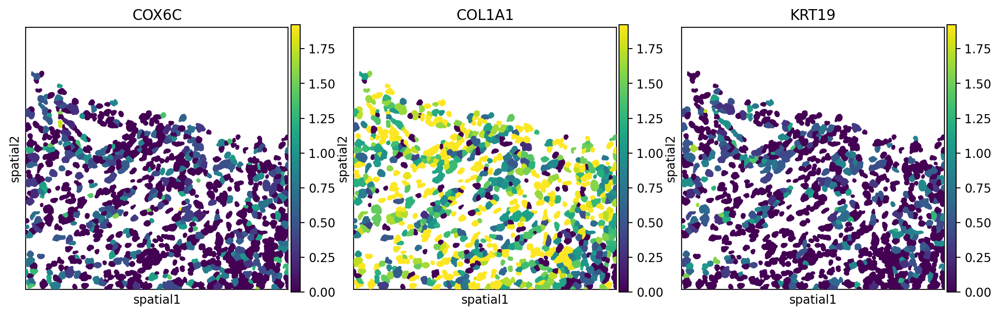

In [12]:
#When we plot the expression of some of these genes, we indeed see some how they are aggregated, or is autocorrelated and co-occurs with other genes
sq.pl.spatial_segment(
    adata2,
    library_id="5",
    seg_cell_id="cell_ID",
    library_key="fov",
    color=["COX6C", "COL1A1", "KRT19"],
    size=60,
    img=False,
    figsize=(4, 4),
    dpi = 200,
    save = "fig-nhood-Morans-I.png"
)


  0%|          | 0/120 [00:00<?, ?/s]

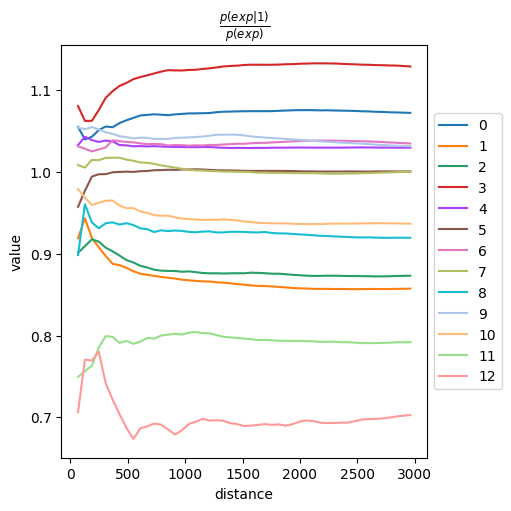

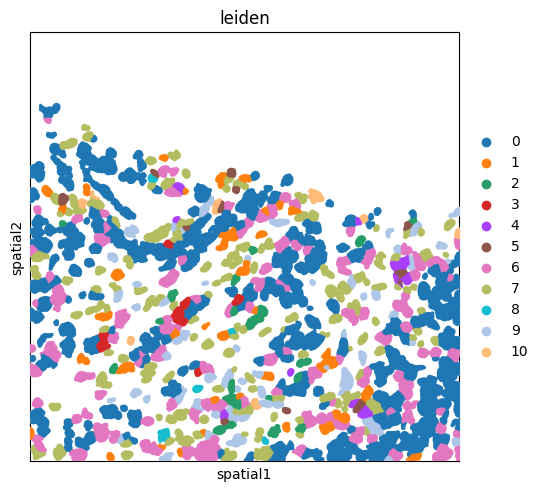

In [15]:
#Spatial co-occurence 
#While Moran’s I quantifies autocorrelation of genes, spatial co-occurence with gr.co_occurence quantifies cell-level co-occurences

sq.gr.co_occurrence(
    adata2,
    cluster_key="leiden",
)

sq.pl.co_occurrence(
    adata2,
    cluster_key="leiden",
    clusters="1",
    #save = "fig-co-occurence1.png"
)
sq.pl.spatial_segment(
    adata2,
    shape="hex",
    color="leiden",
    library_id="5",
    library_key="fov",
    seg_cell_id="cell_ID",
    img=True,
    size=60,
    #save = "fig-co-occurence2.png"
)



/homes/zhanyx3/.local/lib/python3.11/site-packages/numba/np/ufunc/parallel.py:371: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
  warnings.warn(problem)
2025-08-10 10:38:51.545122: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-08-10 10:38:51.549088: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-08-10 10:38:51.558668: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1754840331.574011  752997 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:17548

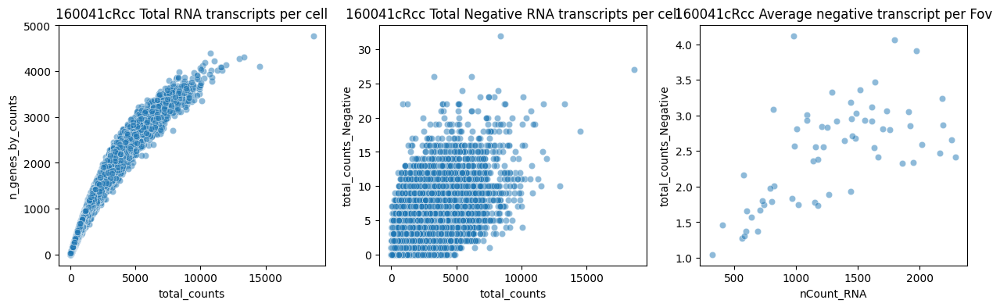

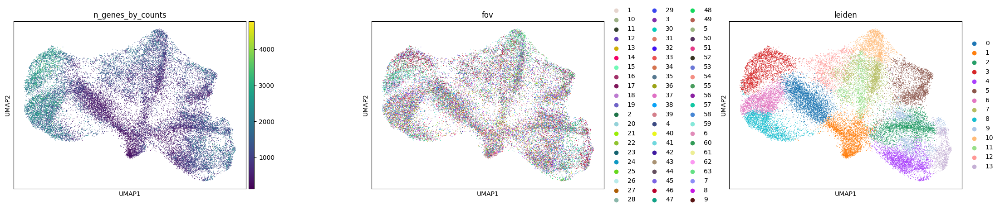

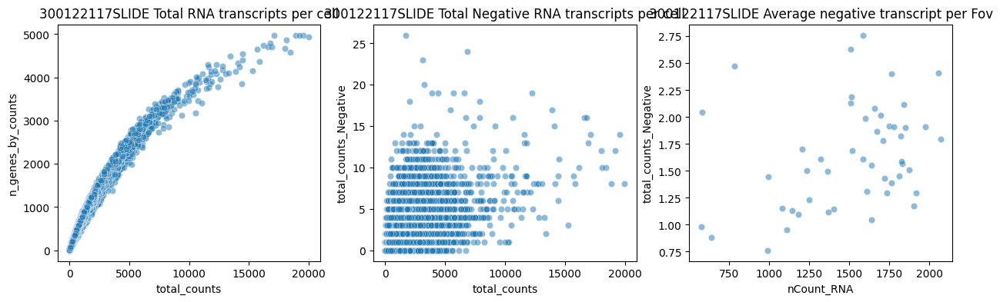

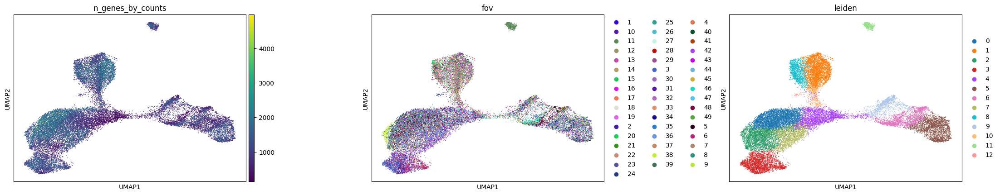

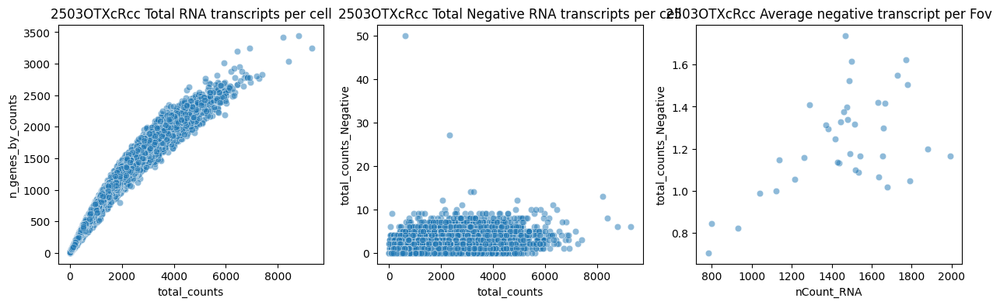

...

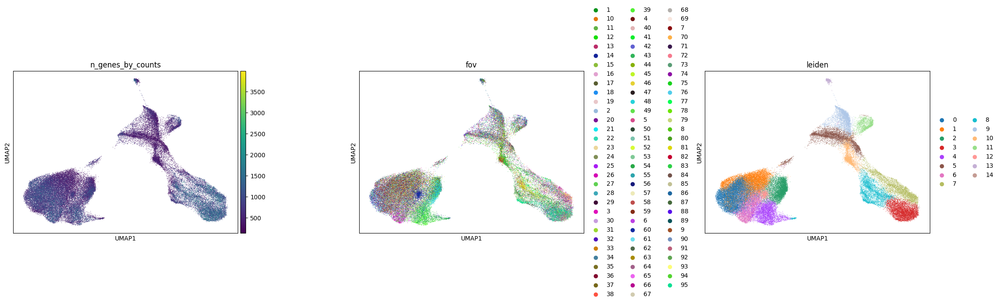

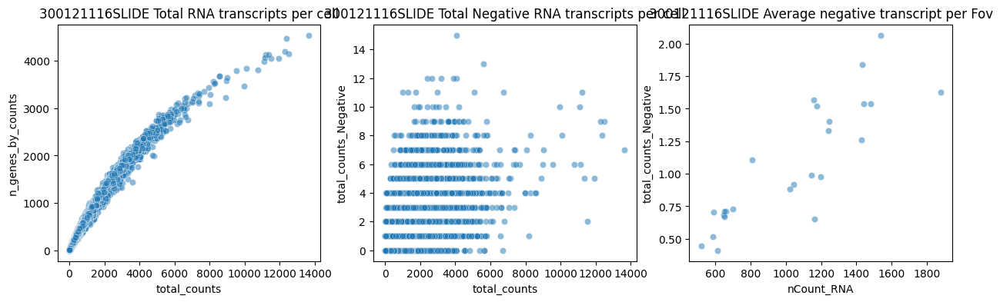

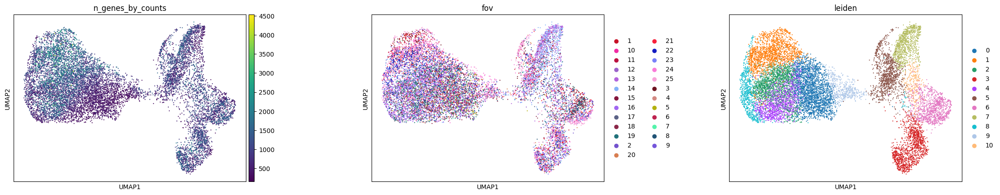

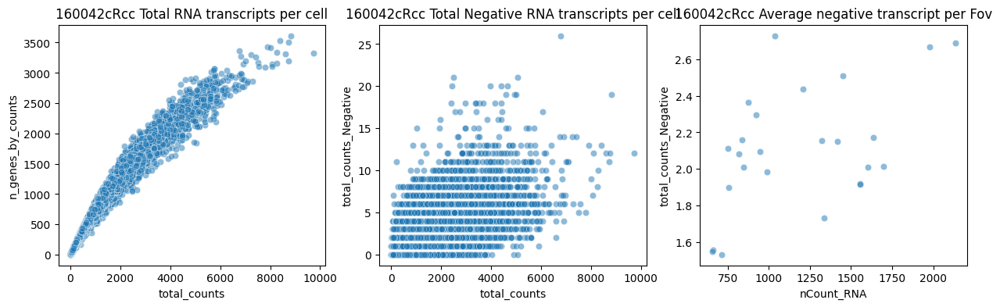

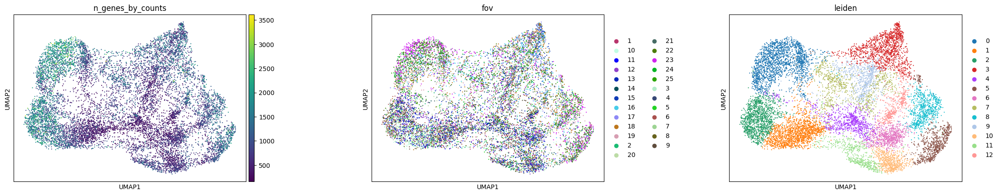

In [2]:
## Analysis

#1. place control targets into separate variables

data_dir = '/homes/zhanyx3/PTPN2_ST/basic_data/'
adatalist = os.listdir(data_dir)

for basic_file in adatalist:
    
    adata = sc.read(os.path.join(data_dir, basic_file))

    adata.var['Negative'] = adata.var_names.str.startswith('Negative')
    adata.var['SystemControl'] = adata.var_names.str.startswith('SystemControl')

    # calculate QC metrics with scanpy, add negative and system controls as qc_var

    sc.pp.calculate_qc_metrics(adata, qc_vars=['Negative','SystemControl'],inplace=True)

    
    ##2 fig one line
    
    ## get sample ID str for naming the plot title
    sample = ''.join(adata.obs['sample'].astype(str).unique())
    
    fig, axs = plt.subplots(1, 3, figsize=(15, 4))

    axs[0].set_title(f"{sample} Total RNA transcripts per cell")
    sns.scatterplot(
        data = adata.obs,
        x='total_counts',
        y='n_genes_by_counts',
        alpha=.5,
        ax=axs[0],
    )

    axs[1].set_title(f"{sample} Total Negative RNA transcripts per cell")
    sns.scatterplot(
        data = adata.obs,
        x='total_counts',
        y='total_counts_Negative',
        alpha=.5,
        ax=axs[1]
    )

    axs[2].set_title(f'{sample} Average negative transcript per Fov')
    sns.scatterplot(
        data=adata.obs,
        x=adata.obs.groupby("fov", observed=True)["nCount_RNA"].mean(),
        y=adata.obs.groupby('fov',observed=True)['total_counts_Negative'].mean(),
        alpha=.5,
        ax=axs[2]
    )
    #plt.savefig('figures/fig-qc-negprob.png',dpi=200)

    ##proportion of negative counts relative to total counts:
    adata.obs['total_counts_Negative'].sum()/adata.obs['total_counts']

    ##2 qc filter
    adata.shape

    #Filter the cells based on the minimum number of counts required
    sc.pp.filter_cells(adata,min_counts=250)

    # Filter the genes based on the minimum number of cells
    sc.pp.filter_genes(adata,min_cells=1000)

    adata.shape

    ##3 normalization and dimension reduction

    adata.layers['counts'] = adata.X.copy()
    sc.pp.normalize_total(adata, inplace = True, exclude_highly_expressed=True)
    sc.pp.log1p(adata)
    sc.pp.pca(adata,n_comps=50)
    sc.pp.neighbors(adata)
    sc.tl.umap(adata,min_dist=.2, spread=1)
    sc.tl.leiden(adata)         
    
    # Visualization on umap
    sc.pl.umap(
        adata,
        color = ['n_genes_by_counts','fov','leiden'],
        wspace=.4
    )

    #Export as .h5ad file
    file_path = os.path.join(os.getcwd(), 'filter_data', f"{sample}_filter_pp.h5ad")
    adata.write(file_path, compression="gzip")


/opt/python/3.11.6/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


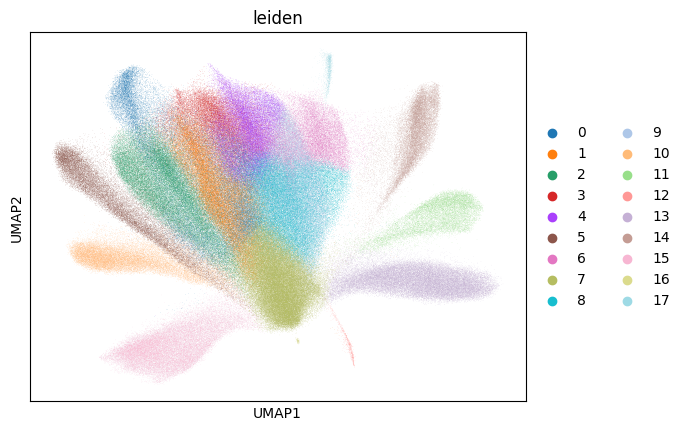

<Figure size 640x480 with 0 Axes>

In [22]:
# Concatenate the AnnData objects

adatal = [ sc.read(os.path.join(data_dir, file)) for file in os.listdir(data_dir)]

# Concatenate the AnnData objects along the observations axis (axis=0)
adatal = sc.concat(adatal,axis=0)

#2. Preprocessing. Before performing batch correction, you need to preprocess your merged AnnData object. This typically involves:
# Basic preprocessing with Scanpy
sc.pp.normalize_total(adatal, target_sum=1e4) # Normalize to 10,000 counts per cell
sc.pp.log1p(adatal) # Log-transform the data
sc.pp.highly_variable_genes(adatal, min_mean=0.0125, max_mean=3, min_disp=0.5) # Select highly variable genes
sc.pp.scale(adatal, max_value=10) # Scale the data to a maximum value of 10
sc.pp.pca(adatal, n_comps=50) # Compute PCA with 50 components
sc.pp.neighbors(adatal)
sc.tl.umap(adatal)
# Using the igraph implementation and a fixed number of iterations can be significantly faster, especially for larger datasets
sc.tl.leiden(adatal, flavor="igraph", n_iterations=2)
sc.pl.umap(adatal, color=["leiden"])

# save un-integrated umap
plt.savefig("/homes/zhanyx3/PTPN2_ST/umap_non-integrated_PTPN2_ST_all.png", dpi=300)


In [33]:
#record leiden cluster before harmony integration
adatal.obs['leiden_pca'] = adatal.obs['leiden']
adatal.obsm['X_umap_pca'] = adatal.obsm['X_umap']

In [40]:
adatal

AnnData object with n_obs × n_vars = 509435 × 6530
    obs: 'fov', 'Area', 'AspectRatio', 'CenterX_local_px', 'CenterY_local_px', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD68', 'Max.CD68', 'Mean.Membrane', 'Max.Membrane', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'SplitRatioToLocal', 'NucArea', 'NucAspectRatio', 'Circularity', 'Eccentricity', 'Perimeter', 'Solidity', 'cell_id', 'assay_type', 'version', 'Run_Tissue_name', 'Panel', 'cellSegmentationSetId', 'cellSegmentationSetName', 'slide_ID', 'CenterX_global_px', 'CenterY_global_px', 'cell_ID', 'unassignedTranscripts', 'median_RNA', 'RNA_quantile_0.75', 'RNA_quantile_0.8', 'RNA_quantile_0.85', 'RNA_quantile_0.9', 'RNA_quantile_0.95', 'RNA_quantile_0.99', 'nCount_RNA', 'nFeature_RNA', 'median_negprobes', 'negprobes_quantile_0.75', 'negprobes_quantile_0.8', 'negprobes_quantile_0.85', 'negprobes_quantile_0.9', 'negprobes_quantile_0.95', 'negprobes_quantile_0.99', 'nCount_negprobes', 'nFeature_negprobes', 'median_falsec

In [41]:
## harmony to integrate multiple slides together
#3. Batch correction with Harmony
# Harmony batch correction with scanpy.external.pp.harmony_integrate
import scanpy as sc
import scanpy.external as sce

sce.pp.harmony_integrate(adatal, "sample")

2025-08-10 13:14:27,295 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2025-08-10 13:16:18,469 - harmonypy - INFO - sklearn.KMeans initialization complete.
2025-08-10 13:16:21,245 - harmonypy - INFO - Iteration 1 of 10
2025-08-10 13:20:31,442 - harmonypy - INFO - Iteration 2 of 10
2025-08-10 13:24:41,913 - harmonypy - INFO - Converged after 2 iterations


KeyError: 'X_pca_harmony'

In [45]:
adatal

AnnData object with n_obs × n_vars = 509435 × 6530
    obs: 'fov', 'Area', 'AspectRatio', 'CenterX_local_px', 'CenterY_local_px', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD68', 'Max.CD68', 'Mean.Membrane', 'Max.Membrane', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'SplitRatioToLocal', 'NucArea', 'NucAspectRatio', 'Circularity', 'Eccentricity', 'Perimeter', 'Solidity', 'cell_id', 'assay_type', 'version', 'Run_Tissue_name', 'Panel', 'cellSegmentationSetId', 'cellSegmentationSetName', 'slide_ID', 'CenterX_global_px', 'CenterY_global_px', 'cell_ID', 'unassignedTranscripts', 'median_RNA', 'RNA_quantile_0.75', 'RNA_quantile_0.8', 'RNA_quantile_0.85', 'RNA_quantile_0.9', 'RNA_quantile_0.95', 'RNA_quantile_0.99', 'nCount_RNA', 'nFeature_RNA', 'median_negprobes', 'negprobes_quantile_0.75', 'negprobes_quantile_0.8', 'negprobes_quantile_0.85', 'negprobes_quantile_0.9', 'negprobes_quantile_0.95', 'negprobes_quantile_0.99', 'nCount_negprobes', 'nFeature_negprobes', 'median_falsec

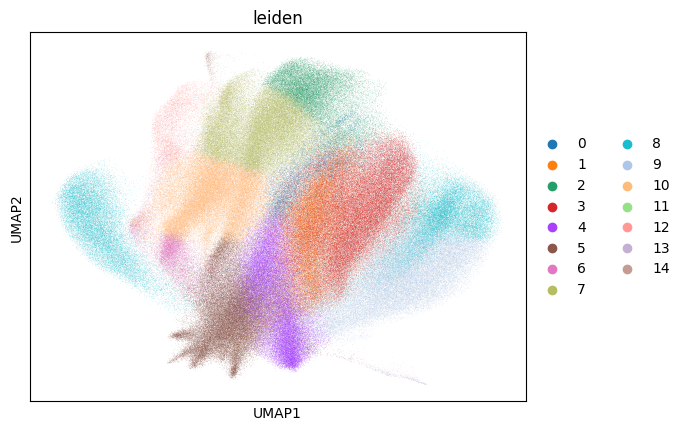

In [50]:
#Compute Nearest Neighbors, using harmony integrated pca
adatal.obsm['X_pca'] = adatal.obsm['X_pca_harmony']
sc.pp.neighbors(adatal)
#Embed the neighbourhood on umap: Finally, compute the UMAP embedding using scanpy.tl.umap. 
#Since sc.pp.neighbors was run on the Harmony-corrected embedding, 
#the UMAP will reflect the batch-corrected data.
sc.tl.umap(adatal)
#Clustering the neighborhood graph
sc.tl.leiden(adatal, flavor="igraph", n_iterations=2)

sc.pl.umap(adatal, color=["leiden"])

In [68]:
# import matplotlib
# matplotlib.use('Agg')
# import matplotlib.pyplot as plt

In [69]:

sc.pl.umap(adatal, color=["leiden"])
# save un-integrated umap
plt.savefig("/homes/zhanyx3/PTPN2_ST/umap_integrated_PTPN2_ST_all.png",dpi=300,transparent=True)


In [59]:
os.makedirs('integrated_data', exist_ok=True)

#Export as .h5ad file
file_path = os.path.join(os.getcwd(), 'integrated_data',"integrated_data.h5ad")
adatal.write(file_path, compression="gzip")


In [2]:
os.makedirs('integrated_data', exist_ok=True)

#read integrated data .h5ad file
file_path = os.path.join(os.getcwd(), 'integrated_data',"integrated_data.h5ad")
adatal = sc.read(file_path)


In [7]:
adatal.obs.columns


Index(['fov', 'Area', 'AspectRatio', 'CenterX_local_px', 'CenterY_local_px',
       'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD68', 'Max.CD68',
       'Mean.Membrane', 'Max.Membrane', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI',
       'Max.DAPI', 'SplitRatioToLocal', 'NucArea', 'NucAspectRatio',
       'Circularity', 'Eccentricity', 'Perimeter', 'Solidity', 'cell_id',
       'assay_type', 'version', 'Run_Tissue_name', 'Panel',
       'cellSegmentationSetId', 'cellSegmentationSetName', 'slide_ID',
       'CenterX_global_px', 'CenterY_global_px', 'cell_ID',
       'unassignedTranscripts', 'median_RNA', 'RNA_quantile_0.75',
       'RNA_quantile_0.8', 'RNA_quantile_0.85', 'RNA_quantile_0.9',
       'RNA_quantile_0.95', 'RNA_quantile_0.99', 'nCount_RNA', 'nFeature_RNA',
       'median_negprobes', 'negprobes_quantile_0.75', 'negprobes_quantile_0.8',
       'negprobes_quantile_0.85', 'negprobes_quantile_0.9',
       'negprobes_quantile_0.95', 'negprobes_quantile_0.99',
       'nCount_neg

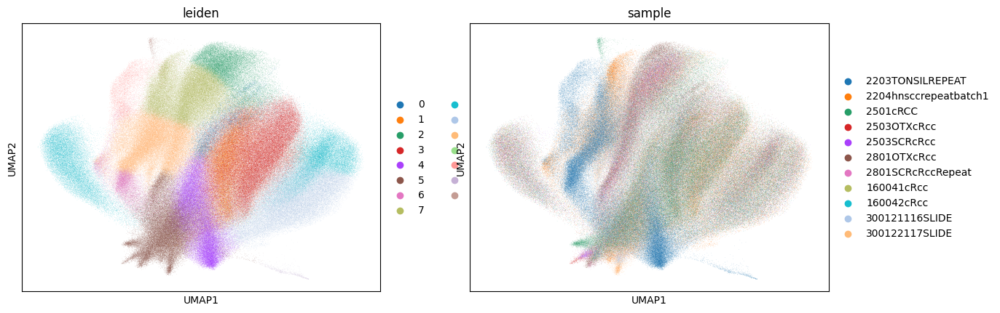

In [8]:
sc.pl.umap(adatal, color=["leiden","sample"])

<Axes: title={'center': ' DAPI'}, xlabel='Mean.DAPI', ylabel='Count'>

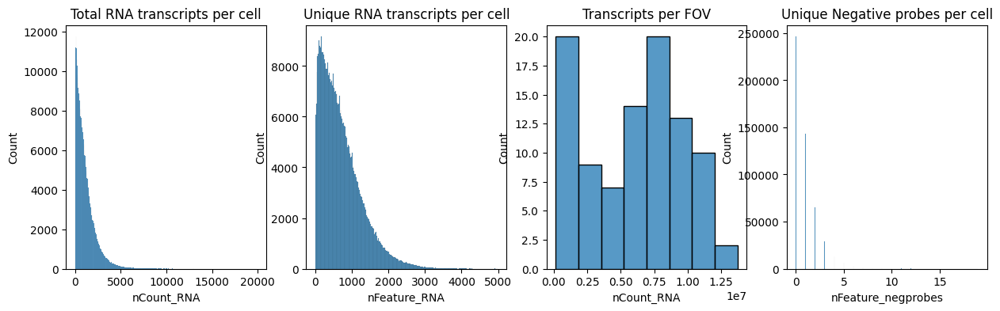

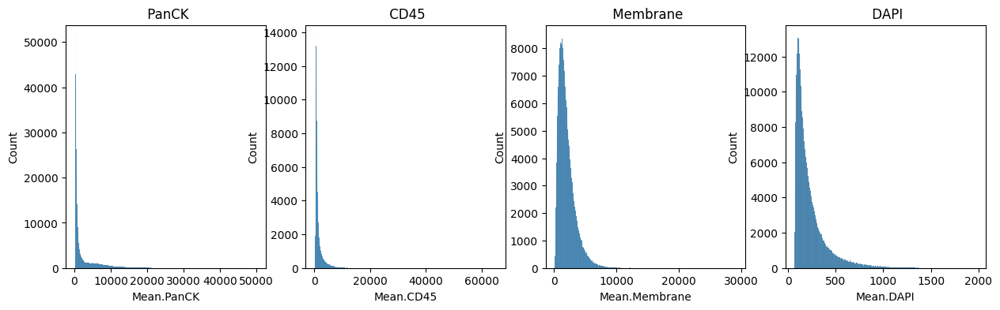

In [12]:
## QC plots as a whole
# plot transcripts distribution

adata = adatal

fig, axs = plt.subplots(1, 4, figsize=(15, 4))

axs[0].set_title(f"Total RNA transcripts per cell")
sns.histplot(
    adata.obs["nCount_RNA"],
    kde=False,
    ax=axs[0],
)

axs[1].set_title(f"Unique RNA transcripts per cell")
sns.histplot(
    adata.obs["nFeature_RNA"],
    kde=False,
    ax=axs[1],
)

axs[2].set_title(f"Transcripts per FOV")
sns.histplot(
    adata.obs.groupby("fov", observed=True)["nCount_RNA"].sum(),
    kde=False,
    ax=axs[2],
)

axs[3].set_title(f"Unique Negative probes per cell")
sns.histplot(
    adata.obs["nFeature_negprobes"],
    kde=False,
    ax=axs[3],
)
    
    
# plot immune intensity distribution
fig, axs = plt.subplots(1, 4, figsize=(15, 4))

axs[0].set_title(f" PanCK")
sns.histplot(
    adata.obs["Mean.PanCK"],
    kde=False,
    ax=axs[0],
)

axs[1].set_title(f" CD45")
sns.histplot(
    adata.obs["Mean.CD45"],
    kde=False,
    ax=axs[1],
)

axs[2].set_title(f" Membrane")
sns.histplot(
    adata.obs["Mean.Membrane"],
    kde=False,
    ax=axs[2],
)

axs[3].set_title(f" DAPI")
sns.histplot(
    adata.obs["Mean.DAPI"],
    kde=False,
    ax=axs[3],
)
 